# CSC 240 Final Project: Clustering
## arXiv Papers Before and After the Release of ChatGPT

Using K-means clustering to group arXiv abstracts based on three writing features:
- `numunit_per100`: numbers and measurement units per 100 words
- `hedge_per100`: hedging words per 100 words
- `promo_per100`: promotional words per 100 words

The clustering algorithm using these three fields, `field` and `period` are kept for interpretation and comparison after clustering.

In [14]:
import os

print("Jupyter is currently looking in:")
print(os.getcwd())

print("\nFiles in this folder:")
for file in os.listdir():
    print(file)

data["v1"] = pd.to_datetime(data["v1"])

print("Date range by period:")
print(
    data.groupby("period")["v1"]
    .agg(["min", "max", "count"])
)

print("\nMonthly counts near the end of the dataset:")
print(
    data[data["v1"] >= "2025-07-01"]
    .groupby(data["v1"].dt.to_period("M"))
    .size()
)

Jupyter is currently looking in:
/Users/anela/Desktop/DSCC240_Final_Project

Files in this folder:
feature_comparison_by_field.csv
cluster_profiles.csv
.DS_Store
cluster_distribution_by_period.csv
cluster_distribution_by_field_period.csv
02_Feature_Engineering.ipynb
data_ming_prospectus_analysis.ipynb
fig_monthly_submissions.png
fig_features_by_field.png
README.md
.gitignore
features_abstracts.csv.gz
clustered_abstracts.csv.gz
03_Clustering.ipynb
arxiv-metadata-oai-snapshot.json
.ipynb_checkpoints
.git
01_Data_Preprocessing.ipynb
abstracts_clean.csv.gz
Date range by period:
                       min                 max   count
period                                                
post   2023-07-01 00:03:33 2025-09-30 23:53:47  557104
pre    2020-01-01 00:01:01 2022-11-29 23:59:20  465209

Monthly counts near the end of the dataset:
v1
2025-07    23472
2025-08    22424
2025-09    25945
Freq: M, dtype: int64


## 1. Import libraries and load the feature dataset

Place `features_abstracts.csv.gz` in the same folder as this notebook. If it is stored elsewhere, update `DATA_PATH`.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score

DATA_PATH = "features_abstracts.csv.gz"

data = pd.read_csv(DATA_PATH)

MAIN = [
    "numunit_per100",
    "hedge_per100",
    "promo_per100"
]

print("Dataset shape:", data.shape)
display(data.head())
print(data[["field", "period"] + MAIN].describe())

Dataset shape: (1022313, 25)


,id,field,period,v1,n_versions,n_words,n_numbers,n_units,n_math_numbers,numbers_per100,...,n_llm,hedge_per100,promo_per100,llm_per100,n_sentences,avg_sent_len,avg_word_len,math_per100,post,specificity_index
0,2001.00113,math,pre,2020-01-01 00:01:01,2,211,2,0,0,0.947867,...,0,0.000000,0.000000,0.0,13,16.230769,5.516588,10.426540,0,1.056682
1,2001.00114,q-bio,pre,2020-01-01 00:01:04,1,136,0,0,0,0.000000,...,0,0.735294,0.000000,0.0,6,22.666667,6.051471,0.000000,0,-0.146660
2,2001.00115,math,pre,2020-01-01 00:09:12,2,32,0,0,0,0.000000,...,0,0.000000,0.000000,0.0,1,32.000000,6.031250,0.000000,0,0.365070
3,2001.00116,cs,pre,2020-01-01 00:15:07,2,194,1,1,0,0.515464,...,0,0.515464,0.515464,0.0,9,21.555556,5.649485,4.123711,0,-0.105698
4,2001.00117,physics,pre,2020-01-01 00:29:27,1,101,0,0,0,0.000000,...,0,0.000000,0.000000,0.0,5,20.200000,6.554455,0.000000,0,0.555635


       numunit_per100  hedge_per100  promo_per100
count    1.022313e+06  1.022313e+06  1.022313e+06
mean     1.000395e+00  3.716632e-01  3.461397e-01
std      2.065243e+00  5.727610e-01  5.725878e-01
min      0.000000e+00  0.000000e+00  0.000000e+00
25%      0.000000e+00  0.000000e+00  0.000000e+00
50%      0.000000e+00  0.000000e+00  0.000000e+00
75%      1.250000e+00  6.329114e-01  5.882353e-01
max      6.451613e+01  9.836066e+00  1.521739e+01


## 2. Check the dataset

Confirm that the required columns exist and inspect missing values, fields, and periods.

In [16]:
required_columns = MAIN + ["field", "period"]
missing_columns = [col for col in required_columns if col not in data.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Missing values:")
print(data[required_columns].isna().sum())

print("\nPapers by field:")
print(data["field"].value_counts().sort_index())

print("\nPapers by period:")
print(data["period"].value_counts())

print("\nField-by-period counts:")
print(pd.crosstab(data["field"], data["period"]))

Missing values:
numunit_per100    0
hedge_per100      0
promo_per100      0
field             0
period            0
dtype: int64

Papers by field:
field
cs         398760
econ         6836
eess        49369
math       165343
physics    359714
q-bio       12375
q-fin        4622
stat        25294
Name: count, dtype: int64

Papers by period:
period
post    557104
pre     465209
Name: count, dtype: int64

Field-by-period counts:
period     post     pre
field                  
cs       241584  157176
econ       4090    2746
eess      25754   23615
math      86383   78960
physics  177324  182390
q-bio      6238    6137
q-fin      2406    2216
stat      13325   11969


## 3. Standardize features within each academic field

For each feature, calculate a Z-score using that field's pre-ChatGPT mean and standard deviation. This accounts for different baseline writing patterns across academic disciplines.

`field` and `period` not clustering inputs. The field-specific pre-period statistics are used for normalization; the labels are used later to interpret the clusters.

In [17]:
pre_stats = (
    data.loc[data["period"] == "pre"]
    .groupby("field")[MAIN]
    .agg(["mean", "std"])
)

X_field = pd.DataFrame(index=data.index)

for feature in MAIN:
    means = data["field"].map(pre_stats[(feature, "mean")])
    stds = data["field"].map(pre_stats[(feature, "std")])

    valid_std = stds.notna() & (stds > 0)
    X_field[feature] = np.nan
    X_field.loc[valid_std, feature] = (
        data.loc[valid_std, feature] - means.loc[valid_std]
    ) / stds.loc[valid_std]

print("Missing standardized values:")
print(X_field.isna().sum())

print("\nInfinite standardized values:")
print(np.isinf(X_field).sum())

display(X_field.describe().round(3))

Missing standardized values:
numunit_per100    0
hedge_per100      0
promo_per100      0
dtype: int64

Infinite standardized values:
numunit_per100    0
hedge_per100      0
promo_per100      0
dtype: int64


,numunit_per100,hedge_per100,promo_per100
count,1022313.000,1022313.000,1022313.000
mean,0.030,-0.007,0.128
std,1.028,0.976,1.100
min,-0.566,-0.806,-0.736
25%,-0.502,-0.682,-0.440
50%,-0.317,-0.426,-0.256
75%,0.178,0.425,0.505
max,33.039,17.503,43.439


## 4. Keep rows with valid clustering features

K-means cannot use rows with missing or infinite standardized values. This cell creates the dataset used for clustering.

In [18]:
valid_rows = (
    X_field.notna().all(axis=1)
    & np.isfinite(X_field).all(axis=1)
    & data["field"].notna()
    & data["period"].isin(["pre", "post"])
)

data_cluster = data.loc[valid_rows].copy()
X_cluster = X_field.loc[valid_rows].copy()

print("Rows in original dataset:", len(data))
print("Rows retained for clustering:", len(data_cluster))
print("Rows excluded:", len(data) - len(data_cluster))

if len(X_cluster) < 100:
    raise ValueError("Too few valid rows remain for clustering. Check the data.")

Rows in original dataset: 1022313
Rows retained for clustering: 1022313
Rows excluded: 0


## 5. Select a possible number of clusters

Compare `k = 2` through `k = 8` on a random sample of up to 10,000 abstracts. Inertia measures within-cluster variation; the silhouette score measures how separated the clusters are. Use both measures and the interpretability of the resulting groups when choosing `k`.

In [19]:
RANDOM_STATE = 42
SAMPLE_SIZE = min(10000, len(X_cluster))

rng = np.random.default_rng(RANDOM_STATE)
sample_positions = rng.choice(
    len(X_cluster),
    size=SAMPLE_SIZE,
    replace=False
)

X_sample = X_cluster.iloc[sample_positions].to_numpy()

k_values = list(range(2, 9))
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    sample_labels = model.fit_predict(X_sample)
    inertias.append(model.inertia_)
    score = silhouette_score(X_sample, sample_labels)
    silhouette_scores.append(score)

    print(f"k={k}: inertia={model.inertia_:.2f}, silhouette={score:.4f}")

k=2: inertia=24214.54, silhouette=0.3932
k=3: inertia=17915.87, silhouette=0.4335
k=4: inertia=12430.78, silhouette=0.4571
k=5: inertia=10828.41, silhouette=0.4295
k=6: inertia=9359.76, silhouette=0.4344
k=7: inertia=8108.41, silhouette=0.4173
k=8: inertia=7424.15, silhouette=0.4190


## 6. Plot the elbow and silhouette results

Look for an elbow where the inertia curve begins to flatten, and consider the silhouette scores. Do not select `k` based on one metric alone.

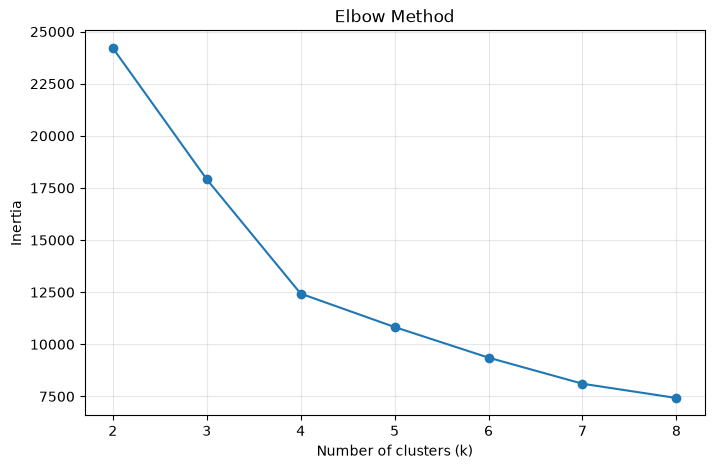

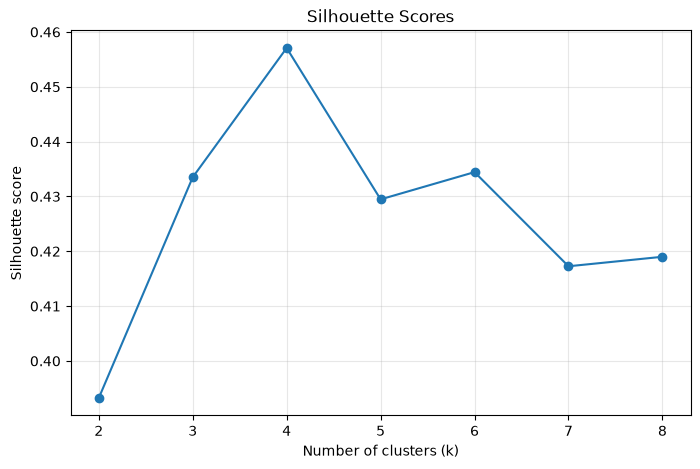

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Scores")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.show()

## 7. Fit the final clustering model

Review the plots above, then set `BEST_K`. The value of 4 below is only a starting choice. MiniBatchKMeans is used for the full dataset because it is more efficient for large datasets.

In [21]:
BEST_K = 4  # Change this after reviewing the plots

final_model = MiniBatchKMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    batch_size=4096,
    n_init=10
)

data_cluster["cluster"] = final_model.fit_predict(X_cluster.to_numpy())

print("Clustering finished.")
print("\nNumber of abstracts in each cluster:")
print(data_cluster["cluster"].value_counts().sort_index())

Clustering finished.

Number of abstracts in each cluster:
cluster
0    174444
1    584467
2     92506
3    170896
Name: count, dtype: int64


## 8. Examine cluster profiles

The table reports average original feature values for each cluster. Cluster numbers are arbitrary labels; they do not represent a ranking.

In [22]:
cluster_profiles = (
    data_cluster.groupby("cluster")[MAIN]
    .mean()
    .round(4)
)

cluster_profiles["n_abstracts"] = (
    data_cluster["cluster"].value_counts().sort_index()
)

cluster_profiles["percent_of_abstracts"] = (
    data_cluster["cluster"].value_counts(normalize=True).sort_index() * 100
).round(2)

display(cluster_profiles)

,numunit_per100,hedge_per100,promo_per100,n_abstracts,percent_of_abstracts
cluster,,,,,
0,0.6972,1.3426,0.2019,174444,17.06
1,0.4516,0.1344,0.1216,584467,57.17
2,5.7160,0.2905,0.2697,92506,9.05
3,0.6341,0.2359,1.3028,170896,16.72


## 9. Compare cluster distributions before and after ChatGPT

This compares the percentage of abstracts assigned to each cluster in the pre and post periods. The period label is not used to form the clusters.

In [23]:
period_distribution = pd.crosstab(
    data_cluster["period"],
    data_cluster["cluster"],
    normalize="index"
) * 100

display(period_distribution.round(2))

cluster,0,1,2,3
period,,,,
post,16.34,54.35,9.47,19.84
pre,17.93,60.55,8.54,12.98


## 10. Visualize the pre/post cluster comparison

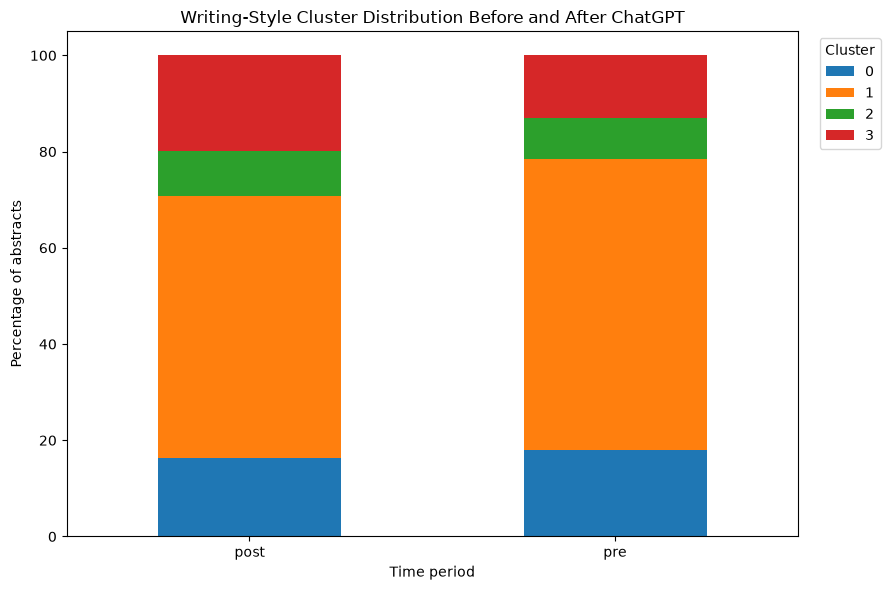

In [24]:
ax = period_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6)
)

ax.set_xlabel("Time period")
ax.set_ylabel("Percentage of abstracts")
ax.set_title("Writing-Style Cluster Distribution Before and After ChatGPT")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Compare clusters within each academic field

The overall pre/post comparison may be affected by changes in the mix of academic fields. This table compares cluster percentages within each field and period.

In [25]:
field_distribution = pd.crosstab(
    [data_cluster["field"], data_cluster["period"]],
    data_cluster["cluster"],
    normalize="index"
) * 100

display(field_distribution.round(2))

cluster             0      1      2      3
field   period                            
cs      post    16.34  49.40  11.74  22.51
        pre     18.43  58.17   9.12  14.28
econ    post    16.36  57.97   8.46  17.21
        pre     19.45  60.52   8.85  11.18
eess    post    16.79  52.46   8.74  22.01
        pre     18.45  58.51   8.82  14.22
math    post    14.74  67.70   6.34  11.22
        pre     15.59  69.92   6.58   7.90
physics post    16.99  54.65   8.41  19.95
        pre     18.35  58.69   9.04  13.92
q-bio   post    15.89  52.26   7.49  24.37
        pre     19.00  59.96   7.63  13.41
q-fin   post    15.79  49.04   9.23  25.94
        pre     17.28  60.29   8.84  13.58
stat    post    17.37  58.03   5.49  19.10
        pre     18.63  62.69   5.98  12.70

## 12. Save the clustering results

The following output files are saved in the same folder as this notebook.

In [26]:
data_cluster.to_csv(
    "clustered_abstracts.csv.gz",
    index=False,
    compression="gzip"
)

cluster_profiles.to_csv("cluster_profiles.csv")
period_distribution.to_csv("cluster_distribution_by_period.csv")
field_distribution.to_csv("cluster_distribution_by_field_period.csv")

print("Saved:")
print("- clustered_abstracts.csv.gz")
print("- cluster_profiles.csv")
print("- cluster_distribution_by_period.csv")
print("- cluster_distribution_by_field_period.csv")

Saved:
- clustered_abstracts.csv.gz
- cluster_profiles.csv
- cluster_distribution_by_period.csv
- cluster_distribution_by_field_period.csv
